# **Lab 8 - Edge Detection**

## Objective
Apply and compare edge detection methods using Python and OpenCV, and investigate how parameter changes affect the detected edges.



- **Task 1:** Sobel, Prewitt and Canny edge detectors on the new image, shown next to the original.
- **Task 2:** Canny with three different threshold pairs, shown side by side, with an explanation of the effect.

### Step 0: Install packages and download the new image (run once)

In [1]:
%pip install -q opencv-python numpy matplotlib

import os

images_dir = os.path.join(os.getcwd(), 'images')
os.makedirs(images_dir, exist_ok=True)

# A new image of my choice: a building facade (lots of straight edges, windows and fine texture)
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/building.jpg'
dest = os.path.join(images_dir, 'building.jpg')

!curl -L -s -o "{dest}" "{url}"
size = os.path.getsize(dest) if os.path.exists(dest) else 0
print(f'building.jpg: {"OK" if size > 0 else "FAILED"} ({size} bytes) -> images/building.jpg')

Note: you may need to restart the kernel to use updated packages.
building.jpg: OK (79718 bytes) -> images/building.jpg


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = os.path.join('images', 'building.jpg')

## **Task 1: Apply Edge Detection Methods**

### Load the selected image
All three detectors work on a single-channel (grayscale) image, so the color image is converted to grayscale first. OpenCV loads color as BGR, so it is converted to RGB only when displayed.

Image shape: (600, 868, 3)


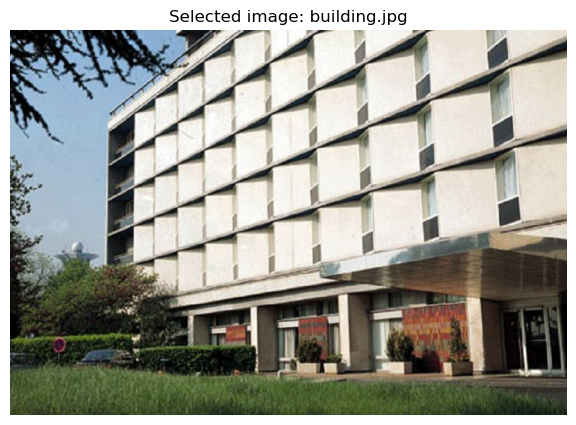

In [3]:
# 1. Load the new image (OpenCV gives BGR)
img = cv2.imread(imgFile)
print('Image shape:', img.shape)

# 2. Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Selected image: building.jpg')
plt.axis('off')
plt.show()

### **Sobel Edge Detector**
Sobel uses two 3x3 kernels (horizontal and vertical derivatives) with built-in smoothing. The image is blurred first to reduce noise, then the two gradients are combined into a magnitude.

In [4]:
# 1. Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 2. Apply Sobel filter in x and y
# cv2.CV_64F handles the high precision needed for derivatives
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

# 3. Calculate Magnitude (Final Edge Map)
sobel_combined = cv2.magnitude(sobelx, sobely)

# 4. Normalize to 0-255 for display
# (The magnitude can be larger than 255, and casting straight to uint8 would wrap those values around,
#  so it is scaled with cv2.normalize instead.)
sobel_final = cv2.normalize(sobel_combined, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

### **Prewitt Edge Detector**
Prewitt is similar to Sobel, but its kernels use equal weights (no extra weight on the center row/column), so it smooths a little less. OpenCV has no built-in Prewitt function, so the kernels are defined manually.

In [5]:
# 1. Grayscale & Blur (reuse the blurred image from above)
# 2. Define Prewitt Kernels manually
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

# 3. Apply filters
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

# 4. Calculate Magnitude (Combine X and Y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)

# 5. Normalize to 8-bit for display
prewitt_final = cv2.normalize(prewitt_combined, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

### **Canny Edge Detector**
Canny computes the gradient, thins the edges (non-maximum suppression) and then uses two thresholds (hysteresis) to decide which edges to keep. A 1:2 or 1:3 ratio between the low and high threshold usually works well.

In [6]:
# Syntax: cv2.Canny(image, low_threshold, high_threshold)
canny_edges = cv2.Canny(gray, 100, 200)

### Original image and the three edge maps

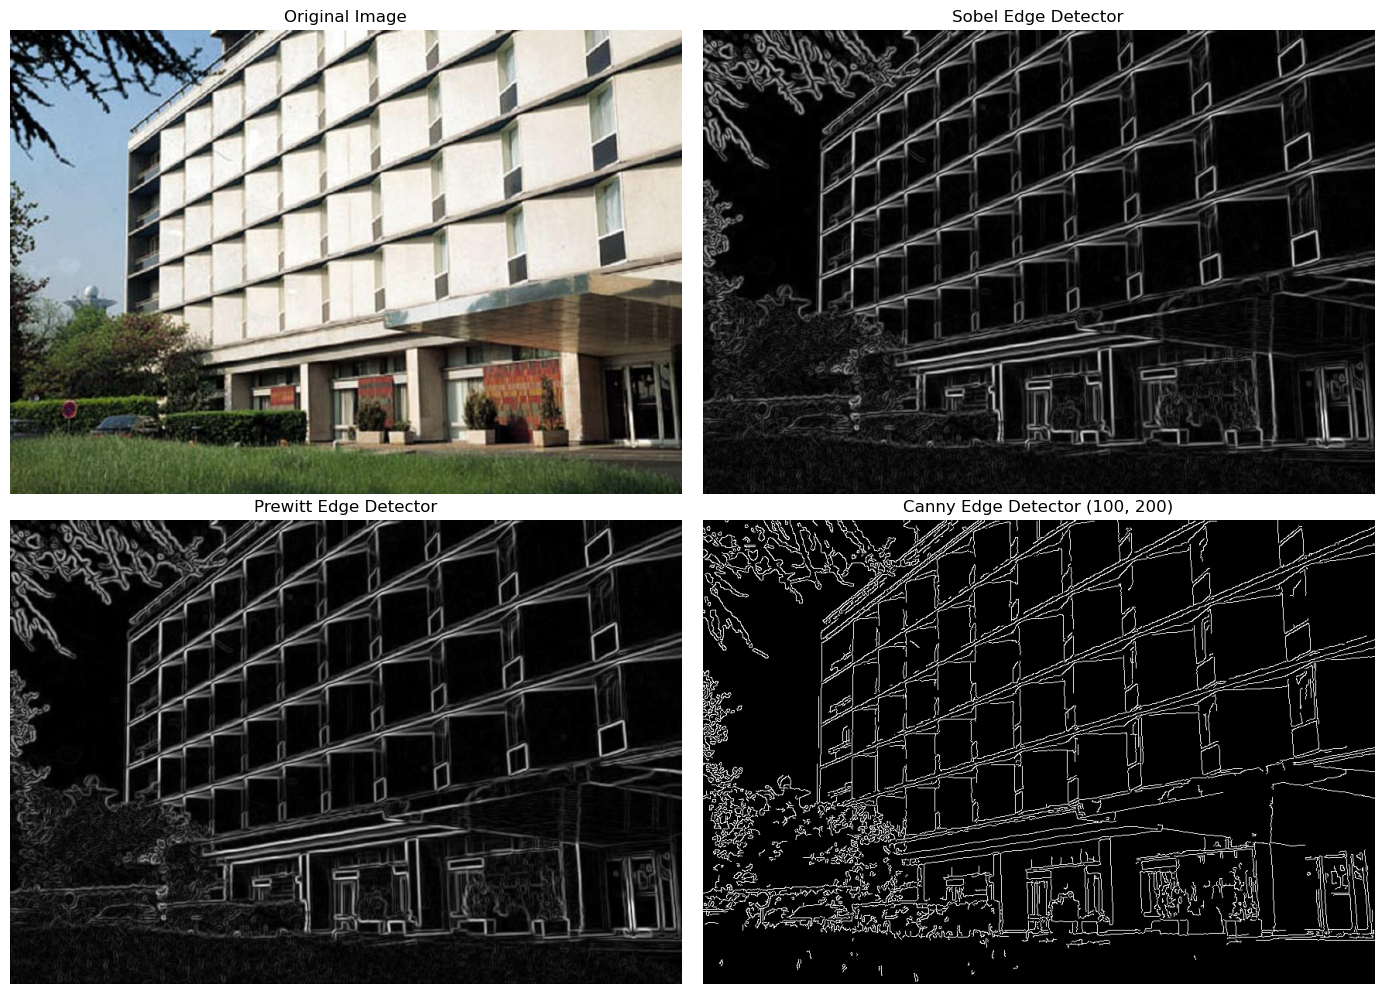

In [7]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detector')
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detector')
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detector (100, 200)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

**Quick comparison.** Sobel and Prewitt produce *gradient magnitude* maps: soft, thick edges whose brightness shows how strong the edge is, and they look nearly identical (Sobel gives slightly more weight to the center pixels, so it is a bit smoother). Canny produces a *binary* map of thin, one-pixel-wide edges, because of its non-maximum suppression and threshold step, so it gives the cleanest, most usable outlines.

## **Task 2: Investigate the Effect of Canny Thresholds**
Canny is applied with three (low, high) threshold pairs, and the edge maps are shown side by side. The number of edge pixels is also counted for each pair.

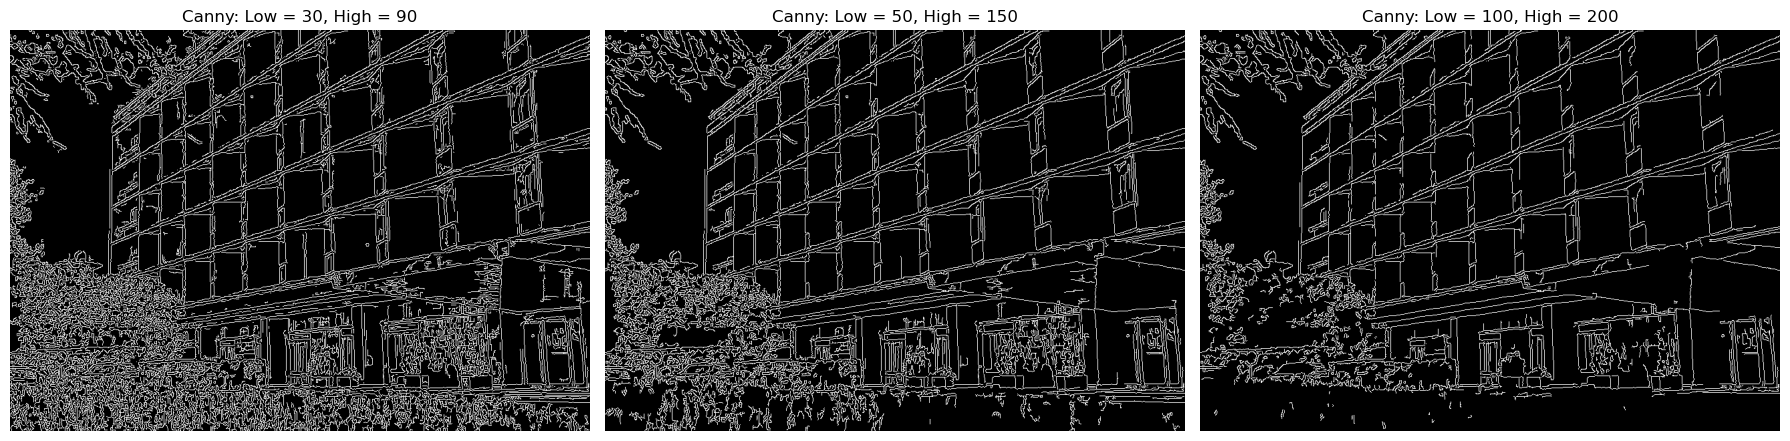

  Low   High   Edge pixels   % of image
   30     90        82,334       15.81%
   50    150        60,463       11.61%
  100    200        42,908        8.24%


In [8]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]

edge_maps = []
for low, high in threshold_pairs:
    edges = cv2.Canny(gray, low, high)
    edge_maps.append(edges)

# Display the three edge maps side by side
plt.figure(figsize=(18, 6))
for i, ((low, high), edges) in enumerate(zip(threshold_pairs, edge_maps), start=1):
    plt.subplot(1, 3, i)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Canny: Low = {low}, High = {high}')
    plt.axis('off')
plt.tight_layout()
plt.show()

# Count the detected edge pixels for each pair
print(f'{"Low":>5} {"High":>6} {"Edge pixels":>13} {"% of image":>12}')
for (low, high), edges in zip(threshold_pairs, edge_maps):
    n = int(np.count_nonzero(edges))
    print(f'{low:>5} {high:>6} {n:>13,} {100 * n / edges.size:>11.2f}%')

### Explanation: how the thresholds affect the edges

Canny uses **hysteresis thresholding**: a pixel whose gradient is above the **high** threshold is a sure edge; a pixel below the **low** threshold is thrown away; a pixel in between is kept only if it is connected to a sure edge.

| Low / High | Edge pixels (my run) | What the result looks like |
|---|---|---|
| 30 / 90 | about 82,000 (about 16% of the image) | Most edges. Fine details show up everywhere: the facade's windows and balconies, but also the leaves, hedges and grass, which turn into a dense mess of small edges (clutter and noise). |
| 50 / 150 | about 60,000 (about 12%) | A balance: the whole building structure and a good amount of detail, with much less clutter in the foliage and grass. |
| 100 / 200 | about 43,000 (about 8%) | Fewest edges. Mostly the strongest boundaries remain (the building's balcony and window grid), and the foliage and grass almost disappear, so the image looks clean but fine details and faint edges are gone. |

**Conclusion.**
- **Lowering the thresholds** makes Canny more sensitive: the number of detected edges goes up and more image detail is visible, including weak edges, but also noise and unimportant texture, which makes the map cluttered.
- **Raising the thresholds** makes Canny stricter: the number of detected edges goes down, only the strong main edges survive, and the map is cleaner. The price is that fine details and low-contrast edges disappear, and a real edge with a weak section can break into gaps.
- There is no single best pair: the right thresholds depend on the image and on whether the goal is to keep as much detail as possible or only the main outlines. The exact pixel counts above come from this image, and the code cell prints them again when you run it.